# Unit 5 — Ensemble Learning for Indian Urban Air Quality & Health Risk Stratification

## Aim
To implement, evaluate, and compare Bagging, Boosting, Stacking, and Voting ensemble learning algorithms (both from scratch using NumPy/Pandas and using Scikit-learn/XGBoost) on the hourly Indian urban air quality dataset (`aqi_2026.csv`) using a leakage-free chronological time-series split.

## Import Libraries

In [ ]:
import os
import json
import time
import warnings
import platform
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, learning_curve
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingRegressor,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)
from xgboost import XGBRegressor, XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

from google.colab import drive

drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/Mini Project'
PROJECT_DIR = os.path.join(PROJECT_ROOT, 'dataset')
DATA_PATH = os.path.join(PROJECT_DIR, 'aqi_2026.csv')
ENS_MODEL_DIR = os.path.join(PROJECT_DIR, 'models', 'ensemble')
FIG_DIR = os.path.join(PROJECT_DIR, 'figures', 'ensemble')
MANIFEST_PATH = os.path.join(PROJECT_DIR, 'models', 'artifact_manifest.json')
for folder in [ENS_MODEL_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)

from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.tree import DecisionTreeRegressor


Mounted at /content/drive


The notebook runs independently in Google Colab. Manual ensemble implementations use library base learners; they do not call the corresponding ensemble estimator. Custom model classes must be defined before loading their saved joblib files.

## Load Dataset

In [ ]:
df = pd.read_csv(DATA_PATH)
df["time_dt"] = pd.to_datetime(df["time"])
# Sort strictly by timestamp then city so chronological operations never split a single hour
df = df.sort_values(["time_dt", "city"]).reset_index(drop=True)

with open(DATA_PATH, "rb") as f:
    dataset_sha256 = hashlib.sha256(f.read()).hexdigest()[:16]

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Time Range: {df['time_dt'].min()} to {df['time_dt'].max()} ({df['time_dt'].nunique():,} unique hours)")
print("Cities:", df["city"].value_counts().to_dict())
print("Missing Values:", int(df.isna().sum().sum()))
display(df[["city", "season", "time", "pm2_5", "pm10", "nitrogen_dioxide", "ozone", "temperature_2m", "wind_speed_10m", "us_aqi", "high_health_risk", "health_risk_level"]].head())

Dataset Shape: 52,704 rows x 72 columns
Time Range: 2025-11-10 00:00:00 to 2026-11-10 23:00:00 (8,784 unique hours)
Cities: {'Bengaluru': 8784, 'Chennai': 8784, 'Delhi': 8784, 'Mumbai': 8784, 'Nagpur': 8784, 'Pune': 8784}
Missing Values: 0


,city,season,time,pm2_5,pm10,nitrogen_dioxide,ozone,temperature_2m,wind_speed_10m,us_aqi,high_health_risk,health_risk_level
0,Bengaluru,Post_Monsoon,2025-11-10 00:00:00,37.4,37.5,64.1,26.0,18.7,8.5,82,0,0
1,Chennai,Post_Monsoon,2025-11-10 00:00:00,35.5,38.1,6.2,126.0,26.4,8.9,125,1,1
2,Delhi,Post_Monsoon,2025-11-10 00:00:00,85.2,169.0,28.7,74.0,17.8,6.9,157,1,2
3,Mumbai,Post_Monsoon,2025-11-10 00:00:00,29.7,30.4,18.7,142.0,23.0,2.9,157,1,2
4,Nagpur,Post_Monsoon,2025-11-10 00:00:00,51.3,53.1,30.6,36.0,18.9,7.1,108,1,1


## Data Preparation and Feature Selection

### Target Leakage & Health-Risk Label Note
- **Regression Target (`us_aqi`)**: Continuous US EPA Air Quality Index. Any columns derived from `us_aqi` (`high_health_risk`, `health_risk_level`) are strictly excluded from the feature matrix.
- **Classification Targets (`high_health_risk`, `health_risk_level`)**: Derived directly from AQI breakpoints (`high_health_risk = 1` when `us_aqi > 100`; `health_risk_level` maps `<=100 -> 0`, `101-150 -> 1`, `>150 -> 2`). Therefore, our classification models predict **AQI-based risk categories** from raw sensor and weather inputs rather than independently predicting clinical health outcomes. `us_aqi` is strictly excluded from the inputs.
- **Spatial Generalization**: Raw identifiers (`city`, `region_zone`, `latitude`, `longitude`, `time`) are excluded from the feature matrix so models learn physical atmospheric relationships rather than memorizing city names.

### Chronological Timestamp-Grouped Split
Because `aqi_2026.csv` is an hourly multi-city time series, a random row split would place neighboring hours (and identical timestamps across different cities) into both training and testing sets. We use an **80/20 chronological split** on unique timestamps (`cutoff = 2026-08-29 19:00:00`), ensuring all 6 cities at a given timestamp remain in the same split.

In [ ]:
NUMERICAL_FEATURES = [
    "pm2_5", "pm10", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide",
    "ozone", "aerosol_optical_depth", "dust", "uv_index",
    "temperature_2m", "relative_humidity_2m", "dew_point_2m", "precipitation",
    "surface_pressure", "cloud_cover", "wind_speed_10m", "wind_direction_10m",
    "shortwave_radiation", "pm_ratio", "stagnation_index", "photochemical_index",
    "is_rush_hour",
]
CATEGORICAL_FEATURES = ["season"]
ALL_INPUT_FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES
SEASON_CATEGORIES = [["Monsoon", "Post_Monsoon", "Summer", "Winter"]]

unique_times = np.sort(df["time_dt"].unique())
cutoff_idx = int(len(unique_times) * 0.80)
cutoff_time = pd.Timestamp(unique_times[cutoff_idx])

train_df = df[df["time_dt"] < cutoff_time].reset_index(drop=True)
test_df = df[df["time_dt"] >= cutoff_time].reset_index(drop=True)

assert len(set(train_df["time"]).intersection(set(test_df["time"]))) == 0, "Timestamp overlap detected!"

X_train = train_df[ALL_INPUT_FEATURES].copy()
X_test = test_df[ALL_INPUT_FEATURES].copy()

y_train_reg = train_df["us_aqi"].values.astype(float)
y_test_reg = test_df["us_aqi"].values.astype(float)

y_train_clf = train_df["high_health_risk"].values.astype(int)
y_test_clf = test_df["high_health_risk"].values.astype(int)

y_train_multi = train_df["health_risk_level"].values.astype(int)
y_test_multi = test_df["health_risk_level"].values.astype(int)

print(f"Chronological Cutoff: {cutoff_time}")
print(f"Train Set: {len(train_df):,} rows ({train_df['time_dt'].min()} -> {train_df['time_dt'].max()})")
print(f"Test  Set: {len(test_df):,} rows ({test_df['time_dt'].min()} -> {test_df['time_dt'].max()})")
print(f"Train Positive Risk Rate: {y_train_clf.mean()*100:.2f}% | Test Positive Risk Rate: {y_test_clf.mean()*100:.2f}%")
print("Train Seasons:", train_df["season"].value_counts().to_dict())
print("Test  Seasons:", test_df["season"].value_counts().to_dict())

Chronological Cutoff: 2026-08-29 19:00:00
Train Set: 42,162 rows (2025-11-10 00:00:00 -> 2026-08-29 18:00:00)
Test  Set: 10,542 rows (2026-08-29 19:00:00 -> 2026-11-10 23:00:00)
Train Positive Risk Rate: 46.18% | Test Positive Risk Rate: 41.06%
Train Seasons: {'Summer': 13248, 'Winter': 12960, 'Monsoon': 12930, 'Post_Monsoon': 3024}
Test  Seasons: {'Post_Monsoon': 5904, 'Monsoon': 4638}


In [ ]:
# Reusable Scikit-learn ColumnTransformer Preprocessors
# 1. Tree-friendly preprocessor (no unnecessary scaling; imputes missing values and encodes season)
def make_tree_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERICAL_FEATURES),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(categories=SEASON_CATEGORIES, handle_unknown="ignore", sparse_output=False)),
                ]),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
    )

# 2. Scaled preprocessor (for distance/margin learners like KNN, SVM, Logistic Regression)
def make_scaled_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]),
                NUMERICAL_FEATURES,
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(categories=SEASON_CATEGORIES, handle_unknown="ignore", sparse_output=False)),
                ]),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
    )

# Fit once to inspect exact transformed feature names
_pre_check = make_tree_preprocessor()
_pre_check.fit(X_train)
TRANSFORMED_FEATURE_NAMES = NUMERICAL_FEATURES + [f"season_{s}" for s in SEASON_CATEGORIES[0]]
print(f"Preprocessed Feature Matrix Width: {len(TRANSFORMED_FEATURE_NAMES)} features")

Preprocessed Feature Matrix Width: 26 features


## Reusable Evaluation Helpers & Baseline Comparison

To compare existing Unit 3 (Regression) and Unit 4 (Classification) models fairly against Unit 5 Ensemble models, we re-evaluate key baseline models on this exact same chronological split. (Previous Unit 3/4 notebooks used a random 80/20 split, so their original scores are kept clearly separated from chronological scores.)

In [ ]:
reg_results = []
clf_results = []
trained_pipelines = {}
reg_predictions = {}
clf_predictions = {}
clf_probabilities = {}


def evaluate_regressor(model_id, display_name, family, impl_type, pipeline, X_tr, y_tr, X_te, y_te, hyperparams):
    t0 = time.perf_counter()
    pipeline.fit(X_tr, y_tr)
    train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_pred = pipeline.predict(X_te)
    pred_time = time.perf_counter() - t1

    mse = float(mean_squared_error(y_te, y_pred))
    rmse = float(np.sqrt(mse))
    mae = float(mean_absolute_error(y_te, y_pred))
    r2 = float(r2_score(y_te, y_pred))

    trained_pipelines[model_id] = pipeline
    reg_predictions[model_id] = y_pred

    row = {
        "Model_ID": model_id,
        "Model": display_name,
        "Family": family,
        "Implementation": impl_type,
        "R2_Score": round(r2, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "Train_Time_s": round(train_time, 4),
        "Predict_Time_s": round(pred_time, 4),
        "Hyperparameters": json.dumps(hyperparams),
    }
    reg_results.append(row)
    return row


def evaluate_classifier(model_id, display_name, family, impl_type, pipeline, X_tr, y_tr, X_te, y_te, hyperparams):
    t0 = time.perf_counter()
    pipeline.fit(X_tr, y_tr)
    train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_pred = pipeline.predict(X_te)
    pred_time = time.perf_counter() - t1

    y_prob = None
    if hasattr(pipeline, "predict_proba"):
        try:
            y_prob = pipeline.predict_proba(X_te)[:, 1]
        except Exception:
            y_prob = None
    elif hasattr(pipeline, "decision_function"):
        dec = pipeline.decision_function(X_te)
        y_prob = 1.0 / (1.0 + np.exp(-np.clip(dec, -15, 15)))

    acc = float(accuracy_score(y_te, y_pred))
    prec_bin = float(precision_score(y_te, y_pred, zero_division=0))
    rec_bin = float(recall_score(y_te, y_pred, zero_division=0))
    f1_bin = float(f1_score(y_te, y_pred, zero_division=0))
    f1_macro = float(f1_score(y_te, y_pred, average="macro", zero_division=0))
    f1_weighted = float(f1_score(y_te, y_pred, average="weighted", zero_division=0))
    auc = float(roc_auc_score(y_te, y_prob)) if y_prob is not None else None

    trained_pipelines[model_id] = pipeline
    clf_predictions[model_id] = y_pred
    if y_prob is not None:
        clf_probabilities[model_id] = y_prob

    row = {
        "Model_ID": model_id,
        "Model": display_name,
        "Family": family,
        "Implementation": impl_type,
        "Accuracy": round(acc, 4),
        "Precision": round(prec_bin, 4),
        "Recall": round(rec_bin, 4),
        "F1_Score": round(f1_bin, 4),
        "Macro_F1": round(f1_macro, 4),
        "Weighted_F1": round(f1_weighted, 4),
        "ROC_AUC": round(auc, 4) if auc is not None else np.nan,
        "Train_Time_s": round(train_time, 4),
        "Predict_Time_s": round(pred_time, 4),
        "Hyperparameters": json.dumps(hyperparams),
    }
    clf_results.append(row)
    return row

In [ ]:
# Re-evaluate Unit 3 & Unit 4 Baseline Models on the Identical Chronological Split
baseline_reg_rows = []
for b_id, b_name, b_pipe in [
    ("baseline_mlr", "Multiple Linear Regression (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("m", LinearRegression())])),
    ("baseline_ridge", "Ridge L2 (alpha=10) (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("m", Ridge(alpha=10.0))])),
    ("baseline_poly2", "Polynomial Deg-2 + Ridge (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("m", Ridge(alpha=100.0))])),
]:
    t0 = time.perf_counter()
    b_pipe.fit(X_train, y_train_reg)
    tr_t = time.perf_counter() - t0
    t1 = time.perf_counter()
    yp = b_pipe.predict(X_test)
    pr_t = time.perf_counter() - t1
    mse = float(mean_squared_error(y_test_reg, yp))
    baseline_reg_rows.append({
        "Model_ID": b_id, "Model": b_name, "Family": "Linear/Poly Baseline", "Implementation": "Baseline (Chronological)",
        "R2_Score": round(float(r2_score(y_test_reg, yp)), 4), "MSE": round(mse, 4),
        "RMSE": round(float(np.sqrt(mse)), 4), "MAE": round(float(mean_absolute_error(y_test_reg, yp)), 4),
        "Train_Time_s": round(tr_t, 4), "Predict_Time_s": round(pr_t, 4),
    })

baseline_clf_rows = []
for b_id, b_name, b_pipe in [
    ("baseline_gnb", "Gaussian Naive Bayes (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("m", GaussianNB())])),
    ("baseline_knn", "KNN (k=5) (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("m", KNeighborsClassifier(n_neighbors=5))])),
    ("baseline_dt", "Pruned Decision Tree (Baseline)", Pipeline([("pre", make_tree_preprocessor()), ("m", DecisionTreeClassifier(max_depth=8, ccp_alpha=0.001, random_state=RANDOM_STATE))])),
    ("baseline_svm_rbf", "RBF-Kernel SVM (Baseline)", Pipeline([("pre", make_scaled_preprocessor()), ("m", SVC(C=5.0, kernel="rbf", probability=False, random_state=RANDOM_STATE))])),
]:
    t0 = time.perf_counter()
    b_pipe.fit(X_train, y_train_clf)
    tr_t = time.perf_counter() - t0
    t1 = time.perf_counter()
    yp = b_pipe.predict(X_test)
    pr_t = time.perf_counter() - t1
    if hasattr(b_pipe, "predict_proba"):
        yprob = b_pipe.predict_proba(X_test)[:, 1]
    else:
        dec = b_pipe.decision_function(X_test)
        yprob = 1.0 / (1.0 + np.exp(-np.clip(dec, -15, 15)))
    baseline_clf_rows.append({
        "Model_ID": b_id, "Model": b_name, "Family": "Single-Model Baseline", "Implementation": "Baseline (Chronological)",
        "Accuracy": round(float(accuracy_score(y_test_clf, yp)), 4),
        "Precision": round(float(precision_score(y_test_clf, yp, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_test_clf, yp, zero_division=0)), 4),
        "F1_Score": round(float(f1_score(y_test_clf, yp, zero_division=0)), 4),
        "Macro_F1": round(float(f1_score(y_test_clf, yp, average="macro", zero_division=0)), 4),
        "Weighted_F1": round(float(f1_score(y_test_clf, yp, average="weighted", zero_division=0)), 4),
        "ROC_AUC": round(float(roc_auc_score(y_test_clf, yprob)), 4),
        "Train_Time_s": round(tr_t, 4), "Predict_Time_s": round(pr_t, 4),
    })

print("=== Chronological Baseline Regression ===")
display(pd.DataFrame(baseline_reg_rows))
print("=== Chronological Baseline Classification ===")
display(pd.DataFrame(baseline_clf_rows))

=== Chronological Baseline Regression ===


,Model_ID,Model,Family,Implementation,R2_Score,MSE,RMSE,MAE,Train_Time_s,Predict_Time_s
0,baseline_mlr,Multiple Linear Regression (Baseline),Linear/Poly Baseline,Baseline (Chronological),0.7178,770.8679,27.7645,18.6370,0.1740,0.0209
1,baseline_ridge,Ridge L2 (alpha=10) (Baseline),Linear/Poly Baseline,Baseline (Chronological),0.7173,772.2965,27.7902,18.6422,0.1939,0.0178
2,baseline_poly2,Polynomial Deg-2 + Ridge (Baseline),Linear/Poly Baseline,Baseline (Chronological),0.7242,753.4278,27.4486,18.9900,1.1654,0.1269


=== Chronological Baseline Classification ===


,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s
0,baseline_gnb,Gaussian Naive Bayes (Baseline),Single-Model Baseline,Baseline (Chronological),0.7404,0.6283,0.9007,0.7402,0.7404,0.7404,0.8984,0.2738,0.0245
1,baseline_knn,KNN (k=5) (Baseline),Single-Model Baseline,Baseline (Chronological),0.8238,0.7611,0.8318,0.7949,0.8202,0.8247,0.8937,0.1851,4.0969
2,baseline_dt,Pruned Decision Tree (Baseline),Single-Model Baseline,Baseline (Chronological),0.8595,0.8430,0.8085,0.8254,0.8539,0.8590,0.9304,0.6897,0.0126
3,baseline_svm_rbf,RBF-Kernel SVM (Baseline),Single-Model Baseline,Baseline (Chronological),0.8705,0.8007,0.9115,0.8525,0.8686,0.8714,0.9529,31.6756,7.6041


In [ ]:
def save_fig(fig, filename):
    p1 = os.path.join(FIG_DIR, filename)
    fig.savefig(p1, dpi=180, bbox_inches="tight")
    plt.close(fig)

def plot_regression_models(model_ids):
    fig, axes = plt.subplots(1, len(model_ids), figsize=(12, 4), squeeze=False)
    for ax, mid in zip(axes[0], model_ids):
        pred = reg_predictions[mid]
        ax.scatter(y_test_reg, pred, s=8, alpha=0.25)
        lo = min(np.min(y_test_reg), np.min(pred))
        hi = max(np.max(y_test_reg), np.max(pred))
        ax.plot([lo, hi], [lo, hi], 'r--')
        ax.set(title=mid, xlabel='Actual AQI', ylabel='Predicted AQI')
    plt.tight_layout()
    plt.show()


def plot_classification_models(model_ids):
    fig, axes = plt.subplots(1, len(model_ids), figsize=(10, 4), squeeze=False)
    for ax, mid in zip(axes[0], model_ids):
        cm = confusion_matrix(y_test_clf, clf_predictions[mid])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax, cbar=False)
        ax.set(title=mid, xlabel='Predicted', ylabel='Actual')
    plt.tight_layout()
    plt.show()

## Algorithm Implementation & Model Training

### 1. Bagging — Random Forest Regressor (Scratch & Library)
Random Forest constructs an ensemble of decorrelated CART decision trees using **bootstrap sampling** (sampling with replacement) and **random feature subsampling** (`max_features='sqrt'`) at every split. Regression averages the continuous predictions across all trees to reduce variance.

In [ ]:
class RandomForestRegressorScratch(RegressorMixin, BaseEstimator):
    def __init__(self, n_estimators=25, max_depth=12, min_samples_split=2, max_features='sqrt', random_state=42):
        self.n_estimators=n_estimators; self.max_depth=max_depth
        self.min_samples_split=min_samples_split; self.max_features=max_features; self.random_state=random_state
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        for i in range(self.n_estimators):
            idx = rng.integers(0, len(X), len(X))
            tree = DecisionTreeRegressor(max_depth=self.max_depth, min_samples_split=self.min_samples_split, max_features=self.max_features, random_state=i)
            self.trees_.append(tree.fit(X[idx], y[idx]))
        self.feature_importances_ = np.mean([t.feature_importances_ for t in self.trees_], axis=0)
        return self
    def predict(self, X):
        return np.mean([t.predict(X) for t in self.trees_], axis=0)

In [ ]:
rf_reg_scratch_params = {"n_estimators": 25, "max_depth": 12, "min_samples_split": 20, "max_features": "sqrt", "random_state": RANDOM_STATE}
rf_reg_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", RandomForestRegressorScratch(**rf_reg_scratch_params)),
])
res = evaluate_regressor(
    "rf_reg_scratch", "Random Forest Regressor (Scratch)", "Random Forest", "Scratch",
    rf_reg_scratch_pipe, X_train, y_train_reg, X_test, y_test_reg, rf_reg_scratch_params
)

rf_reg_lib_params = {"n_estimators": 120, "max_depth": 16, "min_samples_leaf": 4, "max_features": "sqrt", "n_jobs": 1, "random_state": RANDOM_STATE}
rf_reg_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", RandomForestRegressor(**rf_reg_lib_params)),
])
res_lib = evaluate_regressor(
    "rf_reg_lib", "Random Forest Regressor (Scikit-learn)", "Random Forest", "Library",
    rf_reg_lib_pipe, X_train, y_train_reg, X_test, y_test_reg, rf_reg_lib_params
)

display(pd.DataFrame([res, res_lib]))

,Model_ID,Model,Family,Implementation,R2_Score,MSE,RMSE,MAE,Train_Time_s,Predict_Time_s,Hyperparameters
0,rf_reg_scratch,Random Forest Regressor (Scratch),Random Forest,Scratch,0.7536,673.0098,25.9424,16.8566,4.3653,0.0622,"{""n_estimators"": 25, ""max_depth"": 12, ""min_sam..."
1,rf_reg_lib,Random Forest Regressor (Scikit-learn),Random Forest,Library,0.7717,623.5875,24.9717,16.2399,20.5729,0.1877,"{""n_estimators"": 120, ""max_depth"": 16, ""min_sa..."


#### Random Forest Regressor visualization

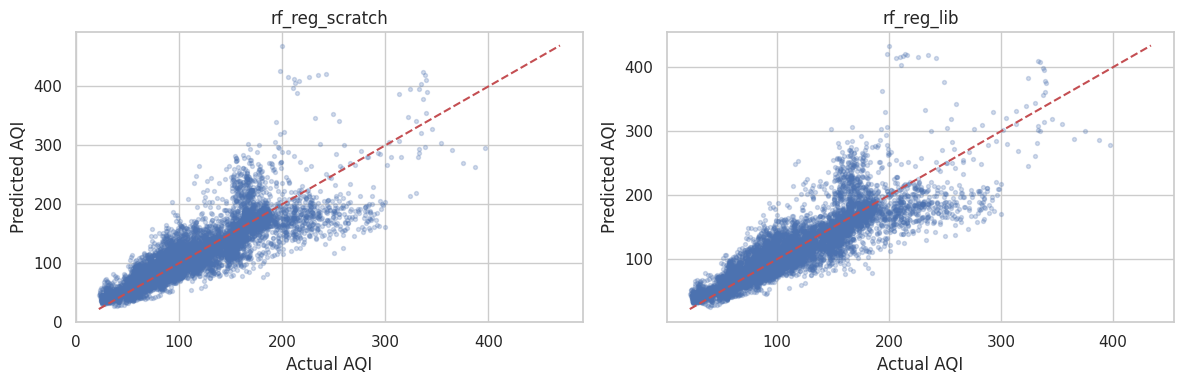

In [ ]:
plot_regression_models(["rf_reg_scratch", "rf_reg_lib"])

### 2. Bagging — Random Forest Classifier (Scratch & Library)
Each bootstrap tree votes for a health-risk category, and majority voting determines the final predicted class while averaged leaf proportions provide posterior probabilities.

In [ ]:
class RandomForestClassifierScratch(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=25, max_depth=12, min_samples_split=2, max_features='sqrt', random_state=42):
        self.n_estimators=n_estimators; self.max_depth=max_depth
        self.min_samples_split=min_samples_split; self.max_features=max_features; self.random_state=random_state
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.classes_ = np.unique(y)
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        for i in range(self.n_estimators):
            idx = rng.integers(0, len(X), len(X))
            tree = DecisionTreeClassifier(max_depth=self.max_depth, min_samples_split=self.min_samples_split, max_features=self.max_features, random_state=i)
            self.trees_.append(tree.fit(X[idx], y[idx]))
        self.feature_importances_ = np.mean([t.feature_importances_ for t in self.trees_], axis=0)
        return self
    def predict_proba(self, X):
        p = np.zeros((len(X), len(self.classes_)))
        for tree in self.trees_:
            p[:, np.searchsorted(self.classes_, tree.classes_)] += tree.predict_proba(X)
        return p / len(self.trees_)
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

In [ ]:
rf_clf_scratch_params = {"n_estimators": 25, "max_depth": 12, "min_samples_split": 20, "max_features": "sqrt", "random_state": RANDOM_STATE}
rf_clf_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", RandomForestClassifierScratch(**rf_clf_scratch_params)),
])
res = evaluate_classifier(
    "rf_clf_scratch", "Random Forest Classifier (Scratch)", "Random Forest", "Scratch",
    rf_clf_scratch_pipe, X_train, y_train_clf, X_test, y_test_clf, rf_clf_scratch_params
)

rf_clf_lib_params = {"n_estimators": 120, "max_depth": 16, "min_samples_leaf": 4, "max_features": "sqrt", "n_jobs": 1, "random_state": RANDOM_STATE}
rf_clf_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", RandomForestClassifier(**rf_clf_lib_params)),
])
res_lib = evaluate_classifier(
    "rf_clf_lib", "Random Forest Classifier (Scikit-learn)", "Random Forest", "Library",
    rf_clf_lib_pipe, X_train, y_train_clf, X_test, y_test_clf, rf_clf_lib_params
)

display(pd.DataFrame([res, res_lib]))

,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s,Hyperparameters
0,rf_clf_scratch,Random Forest Classifier (Scratch),Random Forest,Scratch,0.8792,0.8509,0.8556,0.8533,0.8753,0.8792,0.9530,3.9712,0.0464,"{""n_estimators"": 25, ""max_depth"": 12, ""min_sam..."
1,rf_clf_lib,Random Forest Classifier (Scikit-learn),Random Forest,Library,0.8801,0.8489,0.8614,0.8551,0.8764,0.8802,0.9568,15.8444,0.1213,"{""n_estimators"": 120, ""max_depth"": 16, ""min_sa..."


#### Random Forest Classifier visualization

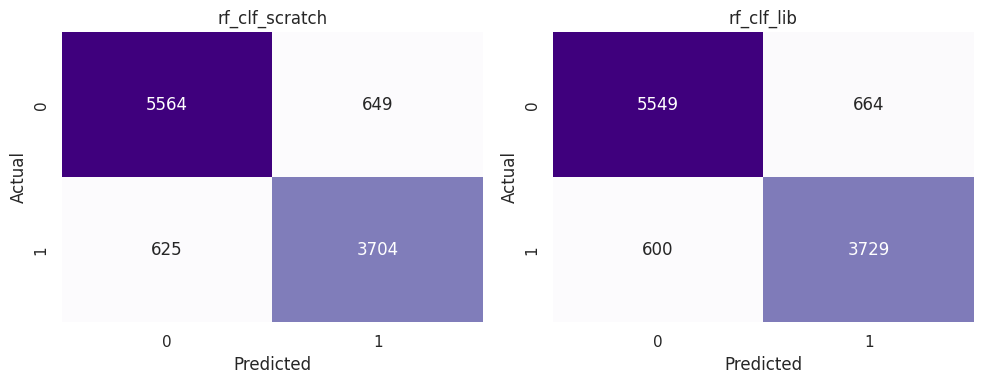

In [ ]:
plot_classification_models(["rf_clf_scratch", "rf_clf_lib"])

### 3. Boosting — AdaBoost Classifier (Scratch & Library)
AdaBoost sequentially trains shallow weak learners (`DecisionTreeClassifierScratch(max_depth=2)` for scratch; `DecisionTreeClassifier(max_depth=2)` for library), increasing the sample weights of misclassified hours so subsequent learners focus on borderline air quality episodes.

In [ ]:
class AdaBoostClassifierScratch(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=35, max_depth=2, learning_rate=0.8, random_state=42):
        self.n_estimators=n_estimators; self.max_depth=max_depth; self.learning_rate=learning_rate; self.random_state=random_state
    def fit(self, X, y):
        y=np.asarray(y); self.classes_=np.unique(y); w=np.ones(len(y))/len(y)
        self.trees_=[]; self.weights_=[]
        for i in range(self.n_estimators):
            tree=DecisionTreeClassifier(max_depth=self.max_depth, random_state=self.random_state+i).fit(X,y,sample_weight=w)
            wrong=tree.predict(X)!=y; error=np.sum(w*wrong)
            if error>=0.5: break
            alpha=self.learning_rate*np.log((1-np.clip(error,1e-10,1-1e-10))/np.clip(error,1e-10,1-1e-10))
            self.trees_.append(tree); self.weights_.append(alpha)
            w*=np.exp(alpha*wrong); w/=w.sum()
            if error==0: break
        if not self.trees_: raise ValueError('No useful weak learner')
        return self
    def predict_proba(self,X):
        score=sum(a*(t.predict(X)==self.classes_[1]) for t,a in zip(self.trees_,self.weights_))/sum(self.weights_)
        p=1/(1+np.exp(-(2*score-1)))
        return np.column_stack([1-p,p])
    def predict(self,X): return self.classes_[np.argmax(self.predict_proba(X),axis=1)]

In [ ]:
ada_scratch_params = {"n_estimators": 35, "max_depth": 2, "learning_rate": 0.8, "random_state": RANDOM_STATE}
ada_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", AdaBoostClassifierScratch(**ada_scratch_params)),
])
res = evaluate_classifier(
    "adaboost_clf_scratch", "AdaBoost Classifier (Scratch)", "AdaBoost", "Scratch",
    ada_scratch_pipe, X_train, y_train_clf, X_test, y_test_clf, ada_scratch_params
)

ada_lib_params = {"n_estimators": 80, "learning_rate": 0.8, "max_depth": 2, "random_state": RANDOM_STATE}
ada_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
        n_estimators=80, learning_rate=0.8, random_state=RANDOM_STATE
    )),
])
res_lib = evaluate_classifier(
    "adaboost_clf_lib", "AdaBoost Classifier (Scikit-learn)", "AdaBoost", "Library",
    ada_lib_pipe, X_train, y_train_clf, X_test, y_test_clf, ada_lib_params
)

display(pd.DataFrame([res, res_lib]))

,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s,Hyperparameters
0,adaboost_clf_scratch,AdaBoost Classifier (Scratch),AdaBoost,Scratch,0.8681,0.8552,0.8173,0.8358,0.8628,0.8677,0.9495,6.8373,0.0389,"{""n_estimators"": 35, ""max_depth"": 2, ""learning..."
1,adaboost_clf_lib,AdaBoost Classifier (Scikit-learn),AdaBoost,Library,0.8751,0.8335,0.8695,0.8511,0.8717,0.8754,0.9549,13.8778,0.1162,"{""n_estimators"": 80, ""learning_rate"": 0.8, ""ma..."


#### AdaBoost visualization

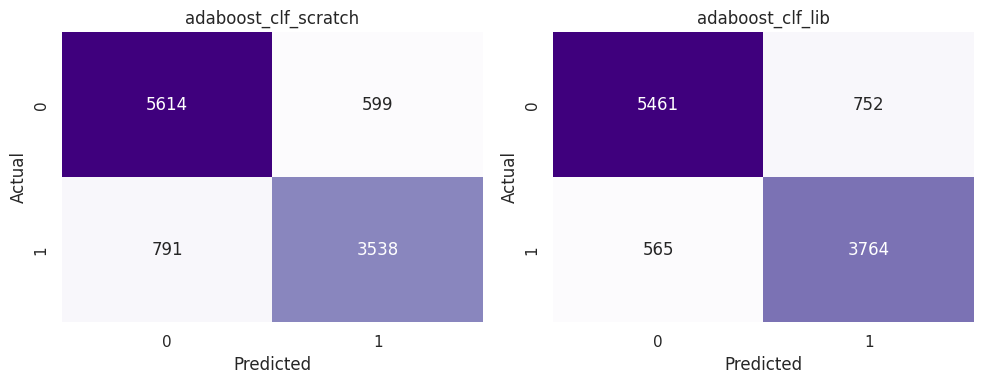

In [ ]:
plot_classification_models(["adaboost_clf_scratch", "adaboost_clf_lib"])

### 4. Boosting — Gradient Boosting Regressor (Scratch & Library)
Gradient Boosting starts from the constant mean prediction $F_0(x) = \bar{y}$ and sequentially fits shallow regression trees to the negative gradient (pseudo-residuals $r = y - F_{m-1}(x)$), updating $F_m(x) = F_{m-1}(x) + \eta h_m(x)$.

In [ ]:
class GradientBoostingRegressorScratch(RegressorMixin, BaseEstimator):
    def __init__(self,n_estimators=50,learning_rate=.1,max_depth=4,subsample=.8,random_state=42):
        self.n_estimators=n_estimators; self.learning_rate=learning_rate; self.max_depth=max_depth; self.subsample=subsample; self.random_state=random_state
    def fit(self,X,y):
        X,y=np.asarray(X),np.asarray(y); self.initial_=y.mean(); pred=np.full(len(y),self.initial_); self.trees_=[]
        rng=np.random.default_rng(self.random_state)
        for i in range(self.n_estimators):
            idx=rng.choice(len(y),max(1,int(len(y)*self.subsample)),replace=False)
            tree=DecisionTreeRegressor(max_depth=self.max_depth,random_state=i).fit(X[idx],(y-pred)[idx])
            pred+=self.learning_rate*tree.predict(X); self.trees_.append(tree)
        self.feature_importances_=np.mean([t.feature_importances_ for t in self.trees_],axis=0)
        return self
    def staged_predict(self,X):
        pred=np.full(len(X),self.initial_)
        for tree in self.trees_:
            pred+=self.learning_rate*tree.predict(X); yield pred.copy()
    def predict(self,X):
        return self.initial_+self.learning_rate*sum(t.predict(X) for t in self.trees_)

In [ ]:
gb_scratch_params = {"n_estimators": 50, "learning_rate": 0.1, "max_depth": 4, "subsample": 0.8, "random_state": RANDOM_STATE}
gb_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", GradientBoostingRegressorScratch(**gb_scratch_params)),
])
res = evaluate_regressor(
    "gb_reg_scratch", "Gradient Boosting Regressor (Scratch)", "Gradient Boosting", "Scratch",
    gb_scratch_pipe, X_train, y_train_reg, X_test, y_test_reg, gb_scratch_params
)

gb_lib_params = {"n_estimators": 150, "learning_rate": 0.08, "max_depth": 4, "subsample": 0.8, "random_state": RANDOM_STATE}
gb_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", GradientBoostingRegressor(**gb_lib_params)),
])
res_lib = evaluate_regressor(
    "gb_reg_lib", "Gradient Boosting Regressor (Scikit-learn)", "Gradient Boosting", "Library",
    gb_lib_pipe, X_train, y_train_reg, X_test, y_test_reg, gb_lib_params
)

display(pd.DataFrame([res, res_lib]))

,Model_ID,Model,Family,Implementation,R2_Score,MSE,RMSE,MAE,Train_Time_s,Predict_Time_s,Hyperparameters
0,gb_reg_scratch,Gradient Boosting Regressor (Scratch),Gradient Boosting,Scratch,0.7678,634.3752,25.1868,16.6334,12.0456,0.0670,"{""n_estimators"": 50, ""learning_rate"": 0.1, ""ma..."
1,gb_reg_lib,Gradient Boosting Regressor (Scikit-learn),Gradient Boosting,Library,0.7775,607.7588,24.6528,16.2431,38.4890,0.0347,"{""n_estimators"": 150, ""learning_rate"": 0.08, ""..."


#### Gradient Boosting visualization

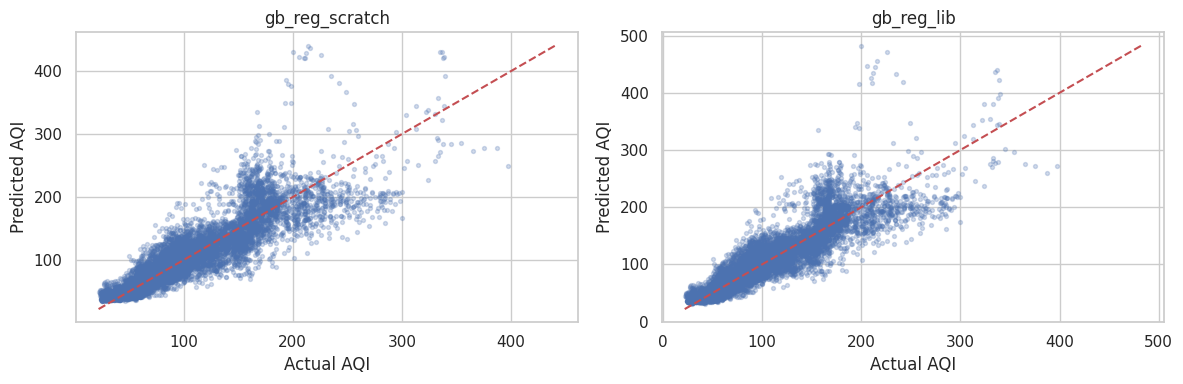

In [ ]:
plot_regression_models(["gb_reg_scratch", "gb_reg_lib"])

### 5. Stacking Classifier (Scratch & Library)
Stacking combines heterogeneous base models — **Decision Tree**, **KNN**, **SVM**, and **Random Forest** — using a **Logistic Regression meta-learner**.
To prevent data leakage on our hourly dataset, the scratch stacking classifier generates **chronological contiguous-block out-of-fold predictions** (never predicting on rows used to fit that fold's base learner), while the library `StackingClassifier` uses 4-fold contiguous chronological blocks (`KFold(n_splits=4, shuffle=False)`).

In [ ]:
class StackingClassifierScratch(ClassifierMixin, BaseEstimator):
    def __init__(self,estimators,final_estimator,n_folds=4):
        self.estimators=estimators; self.final_estimator=final_estimator; self.n_folds=n_folds
    def fit(self,X,y):
        X,y=np.asarray(X),np.asarray(y); self.classes_=np.unique(y); rows=[]; targets=[]; scores=[]
        for tr,va in TimeSeriesSplit(n_splits=self.n_folds).split(X):
            models=[clone(m).fit(X[tr],y[tr]) for _,m in self.estimators]
            rows.append(np.column_stack([m.predict_proba(X[va])[:,1] for m in models])); targets.append(y[va])
            scores.append([accuracy_score(y[va],m.predict(X[va])) for m in models])
        self.oof_base_scores_=dict(zip([n for n,_ in self.estimators],np.mean(scores,axis=0)))
        self.meta_=clone(self.final_estimator).fit(np.vstack(rows),np.concatenate(targets))
        self.models_=[clone(m).fit(X,y) for _,m in self.estimators]; return self
    def predict_proba(self,X): return self.meta_.predict_proba(np.column_stack([m.predict_proba(X)[:,1] for m in self.models_]))
    def predict(self,X): return self.classes_[np.argmax(self.predict_proba(X),axis=1)]

In [ ]:
from sklearn.model_selection import KFold

# Scratch Stacking: manual stacking with library base learners and logistic regression
scratch_base_learners = [
    ("dt", DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ("svm", make_pipeline(StandardScaler(), CalibratedClassifierCV(LinearSVC(C=1.0), cv=3))),
    ("rf", RandomForestClassifierScratch(n_estimators=10, max_depth=8, random_state=RANDOM_STATE)),
]

stack_scratch_params = {"base_learners": ["DecisionTree", "KNeighbors", "CalibratedLinearSVC", "RandomForestScratch"], "meta_learner": "LogisticRegression", "n_folds": 4}
stack_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", StackingClassifierScratch(
        estimators=scratch_base_learners,
        final_estimator=LogisticRegression(max_iter=1000),
        n_folds=4,
    )),
])
res = evaluate_classifier(
    "stacking_clf_scratch", "Stacking Classifier (Scratch)", "Stacking", "Scratch",
    stack_scratch_pipe, X_train, y_train_clf, X_test, y_test_clf, stack_scratch_params
)

# Library Stacking: Scikit-learn DecisionTree, KNN, Calibrated LinearSVC, RandomForest + LogisticRegression meta-learner
lib_base_learners = [
    ("dt", DecisionTreeClassifier(max_depth=10, ccp_alpha=0.0005, random_state=RANDOM_STATE)),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ("svm", make_pipeline(StandardScaler(), CalibratedClassifierCV(LinearSVC(C=1.0, random_state=RANDOM_STATE), cv=3))),
    ("rf", RandomForestClassifier(n_estimators=80, max_depth=14, max_features="sqrt", n_jobs=1, random_state=RANDOM_STATE)),
]
chrono_cv = KFold(n_splits=4, shuffle=False)
stack_lib_params = {"base_learners": ["DecisionTree", "KNeighbors", "CalibratedLinearSVC", "RandomForest"], "meta_learner": "LogisticRegression", "cv": "Blocked KFold (not forward-only)"}
stack_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", StackingClassifier(
        estimators=lib_base_learners,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        cv=chrono_cv,
        n_jobs=1,
    )),
])
res_lib = evaluate_classifier(
    "stacking_clf_lib", "Stacking Classifier (Scikit-learn)", "Stacking", "Library",
    stack_lib_pipe, X_train, y_train_clf, X_test, y_test_clf, stack_lib_params
)

display(pd.DataFrame([res, res_lib]))
print("Scratch Stacking Forward OOF Base Accuracies:", trained_pipelines["stacking_clf_scratch"].named_steps["model"].oof_base_scores_)

,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s,Hyperparameters
0,stacking_clf_scratch,Stacking Classifier (Scratch),Stacking,Scratch,0.8746,0.8269,0.8785,0.8519,0.8716,0.8751,0.9523,19.6459,4.0281,"{""base_learners"": [""DecisionTree"", ""KNeighbors..."
1,stacking_clf_lib,Stacking Classifier (Scikit-learn),Stacking,Library,0.8809,0.8496,0.8626,0.8560,0.8772,0.8810,0.9551,60.2735,2.8570,"{""base_learners"": [""DecisionTree"", ""KNeighbors..."


Scratch Stacking Forward OOF Base Accuracies: {'dt': np.float64(0.8458847248576851), 'knn': np.float64(0.8380277514231499), 'svm': np.float64(0.8868299335863378), 'rf': np.float64(0.8762749051233396)}


#### Stacking visualization

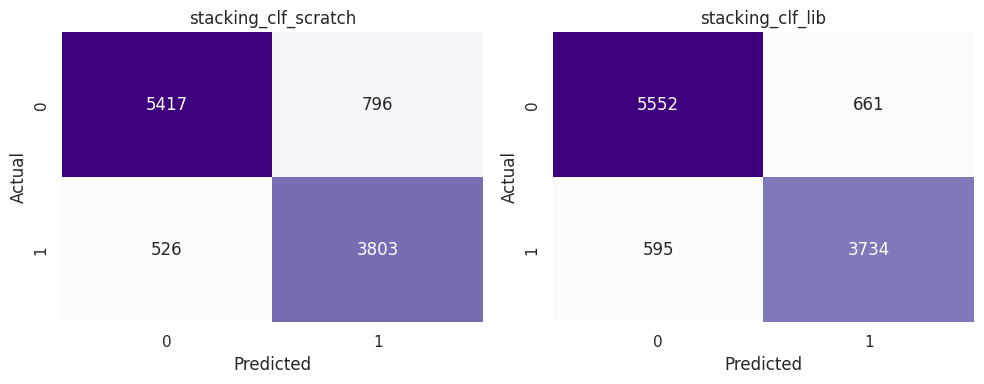

In [ ]:
plot_classification_models(["stacking_clf_scratch", "stacking_clf_lib"])

### 6. Hard Voting & 7. Soft Voting Classifiers (Scratch & Library)
- **Hard Voting**: Combines discrete class label predictions via majority vote across diverse base models.
- **Soft Voting**: Averages aligned predicted class probabilities across probabilistic base learners (`predict_proba`) and selects the highest-probability class.

In [ ]:
class SoftVotingClassifierScratch(ClassifierMixin, BaseEstimator):
    def __init__(self,estimators): self.estimators=estimators
    def fit(self,X,y):
        self.classes_=np.unique(y); self.models_=[clone(m).fit(X,y) for _,m in self.estimators]; return self
    def predict_proba(self,X): return np.mean([m.predict_proba(X) for m in self.models_],axis=0)
    def predict(self,X): return self.classes_[np.argmax(self.predict_proba(X),axis=1)]

class HardVotingClassifierScratch(SoftVotingClassifierScratch):
    def predict_proba(self,X):
        return np.mean([(m.predict(X)[:,None]==self.classes_).astype(float) for m in self.models_],axis=0)

In [ ]:
# Hard Voting (Scratch vs Library)
hv_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", HardVotingClassifierScratch(estimators=scratch_base_learners)),
])
res_hv_s = evaluate_classifier(
    "hard_voting_clf_scratch", "Hard Voting Classifier (Scratch)", "Hard Voting", "Scratch",
    hv_scratch_pipe, X_train, y_train_clf, X_test, y_test_clf, {"estimators": ["DT", "KNN", "LinearSVM", "RF"], "voting": "hard"}
)

hv_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", VotingClassifier(estimators=lib_base_learners, voting="hard", n_jobs=1)),
])
res_hv_l = evaluate_classifier(
    "hard_voting_clf_lib", "Hard Voting Classifier (Scikit-learn)", "Hard Voting", "Library",
    hv_lib_pipe, X_train, y_train_clf, X_test, y_test_clf, {"estimators": ["DT", "KNN", "CalibratedSVC", "RF"], "voting": "hard"}
)

#### Hard Voting visualization

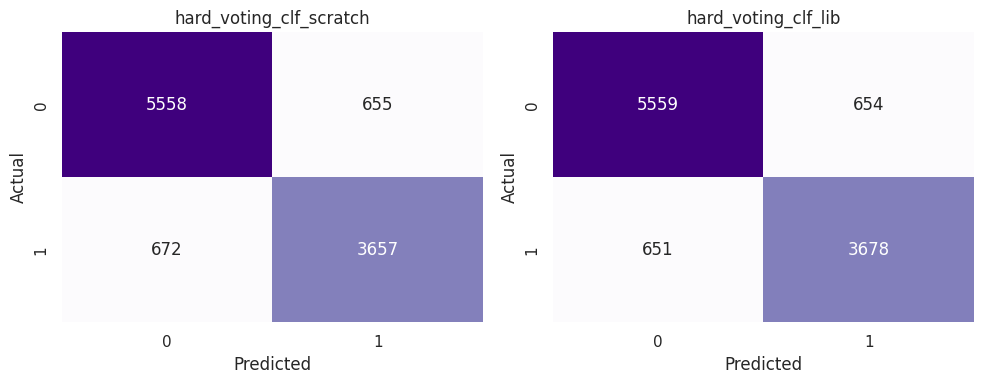

In [ ]:
plot_classification_models(["hard_voting_clf_scratch", "hard_voting_clf_lib"])

### 7. Soft Voting Classifier

In [ ]:
# Soft Voting (Scratch vs Library)
sv_scratch_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", SoftVotingClassifierScratch(estimators=scratch_base_learners)),
])
res_sv_s = evaluate_classifier(
    "soft_voting_clf_scratch", "Soft Voting Classifier (Scratch)", "Soft Voting", "Scratch",
    sv_scratch_pipe, X_train, y_train_clf, X_test, y_test_clf, {"estimators": ["DT", "KNN", "LinearSVM", "RF"], "voting": "soft"}
)

sv_lib_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", VotingClassifier(estimators=lib_base_learners, voting="soft", n_jobs=1)),
])
res_sv_l = evaluate_classifier(
    "soft_voting_clf_lib", "Soft Voting Classifier (Scikit-learn)", "Soft Voting", "Library",
    sv_lib_pipe, X_train, y_train_clf, X_test, y_test_clf, {"estimators": ["DT", "KNN", "CalibratedSVC", "RF"], "voting": "soft"}
)

display(pd.DataFrame([res_hv_s, res_hv_l, res_sv_s, res_sv_l]))

,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s,Hyperparameters
0,hard_voting_clf_scratch,Hard Voting Classifier (Scratch),Hard Voting,Scratch,0.8741,0.8481,0.8448,0.8464,0.8699,0.8741,0.9235,4.1812,2.7431,"{""estimators"": [""DT"", ""KNN"", ""LinearSVM"", ""RF""..."
1,hard_voting_clf_lib,Hard Voting Classifier (Scikit-learn),Hard Voting,Library,0.8762,0.8490,0.8496,0.8493,0.8721,0.8762,NaN,12.9678,2.8419,"{""estimators"": [""DT"", ""KNN"", ""CalibratedSVC"", ..."
2,soft_voting_clf_scratch,Soft Voting Classifier (Scratch),Soft Voting,Scratch,0.8698,0.8173,0.8794,0.8472,0.8669,0.8704,0.9521,2.9063,4.4243,"{""estimators"": [""DT"", ""KNN"", ""LinearSVM"", ""RF""..."
3,soft_voting_clf_lib,Soft Voting Classifier (Scikit-learn),Soft Voting,Library,0.8695,0.8180,0.8773,0.8466,0.8665,0.8701,0.9526,13.0142,2.8053,"{""estimators"": [""DT"", ""KNN"", ""CalibratedSVC"", ..."


#### Soft Voting visualization

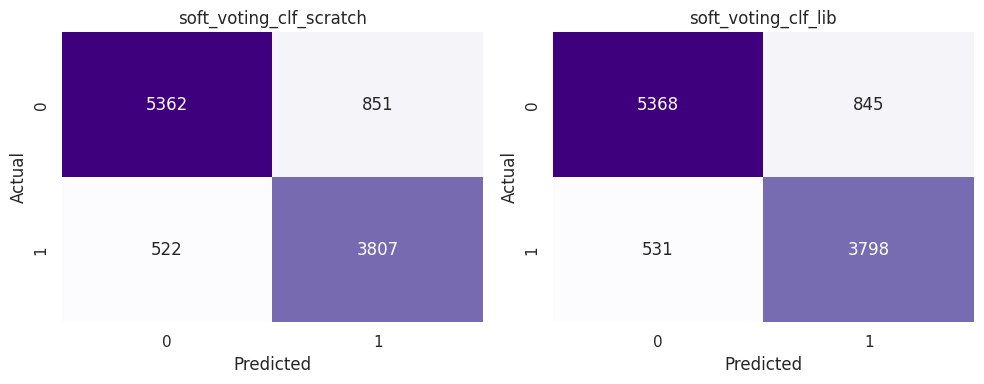

In [ ]:
plot_classification_models(["soft_voting_clf_scratch", "soft_voting_clf_lib"])

### 8. Advanced Ensemble — XGBoost Regressor & Classifier (Library)
XGBoost uses regularized second-order gradient boosting (Taylor expansion with L1/L2 leaf penalties and histogram tree splitting). We perform a lightweight time-series `RandomizedSearchCV` (`TimeSeriesSplit(n_splits=3)`) to select well-regularized hyperparameters without exhaustive overhead.

In [ ]:
tscv = TimeSeriesSplit(n_splits=3)

# XGBoost Regressor with lightweight TimeSeriesSplit tuning
xgb_reg_base = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", XGBRegressor(objective="reg:squarederror", tree_method="hist", n_jobs=4, random_state=RANDOM_STATE)),
])
xgb_reg_search = RandomizedSearchCV(
    xgb_reg_base,
    param_distributions={
        "model__n_estimators": [120, 200],
        "model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    },
    n_iter=6,
    cv=tscv,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
xgb_reg_search.fit(X_train, y_train_reg)
best_xgb_reg_params = {k.replace("model__", ""): v for k, v in xgb_reg_search.best_params_.items()}
best_xgb_reg_params.update({"objective": "reg:squarederror", "tree_method": "hist", "random_state": RANDOM_STATE})

xgb_reg_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", XGBRegressor(**best_xgb_reg_params, n_jobs=4)),
])
res_xgb_r = evaluate_regressor(
    "xgb_reg_lib", "XGBoost Regressor (XGBoost)", "XGBoost", "Library",
    xgb_reg_pipe, X_train, y_train_reg, X_test, y_test_reg, best_xgb_reg_params
)

#### XGBoost Regressor visualization

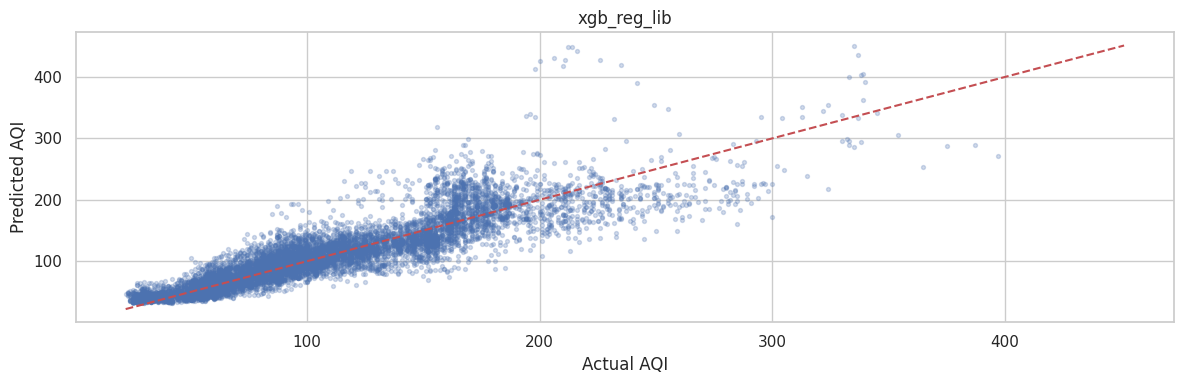

In [ ]:
plot_regression_models(["xgb_reg_lib"])

### XGBoost Classifier

In [ ]:
# XGBoost Classifier with lightweight TimeSeriesSplit tuning
xgb_clf_base = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=4, random_state=RANDOM_STATE)),
])
xgb_clf_search = RandomizedSearchCV(
    xgb_clf_base,
    param_distributions={
        "model__n_estimators": [120, 200],
        "model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    },
    n_iter=6,
    cv=tscv,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
xgb_clf_search.fit(X_train, y_train_clf)
best_xgb_clf_params = {k.replace("model__", ""): v for k, v in xgb_clf_search.best_params_.items()}
best_xgb_clf_params.update({"eval_metric": "logloss", "tree_method": "hist", "random_state": RANDOM_STATE})

xgb_clf_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", XGBClassifier(**best_xgb_clf_params, n_jobs=4)),
])
res_xgb_c = evaluate_classifier(
    "xgb_clf_lib", "XGBoost Classifier (XGBoost)", "XGBoost", "Library",
    xgb_clf_pipe, X_train, y_train_clf, X_test, y_test_clf, best_xgb_clf_params
)

# Secondary 3-Tier Multi-Class Ensemble Classifier (for severity stratification in live simulator)
xgb_multi_pipe = Pipeline([
    ("pre", make_tree_preprocessor()),
    ("model", XGBClassifier(
        n_estimators=best_xgb_clf_params["n_estimators"],
        max_depth=best_xgb_clf_params["max_depth"],
        learning_rate=best_xgb_clf_params["learning_rate"],
        subsample=best_xgb_clf_params["subsample"],
        colsample_bytree=best_xgb_clf_params["colsample_bytree"],
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=4,
        random_state=RANDOM_STATE,
    )),
])
xgb_multi_pipe.fit(X_train, y_train_multi)
y_pred_multi = xgb_multi_pipe.predict(X_test)
multi_acc = float(accuracy_score(y_test_multi, y_pred_multi))
multi_macro_f1 = float(f1_score(y_test_multi, y_pred_multi, average="macro"))
print(f"Secondary 3-Tier XGBoost Severity -> Test Accuracy: {multi_acc:.4f} | Macro F1: {multi_macro_f1:.4f}")
display(pd.DataFrame([res_xgb_r]))
display(pd.DataFrame([res_xgb_c]))

Secondary 3-Tier XGBoost Severity -> Test Accuracy: 0.8077 | Macro F1: 0.7606


,Model_ID,Model,Family,Implementation,R2_Score,MSE,RMSE,MAE,Train_Time_s,Predict_Time_s,Hyperparameters
0,xgb_reg_lib,XGBoost Regressor (XGBoost),XGBoost,Library,0.7813,597.4758,24.4433,16.1603,1.0807,0.0653,"{""subsample"": 0.8, ""n_estimators"": 200, ""max_d..."


,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s,Hyperparameters
0,xgb_clf_lib,XGBoost Classifier (XGBoost),XGBoost,Library,0.8762,0.8147,0.9041,0.8571,0.874,0.877,0.9595,1.2316,0.0448,"{""subsample"": 0.8, ""n_estimators"": 200, ""max_d..."


#### XGBoost Classifier visualization

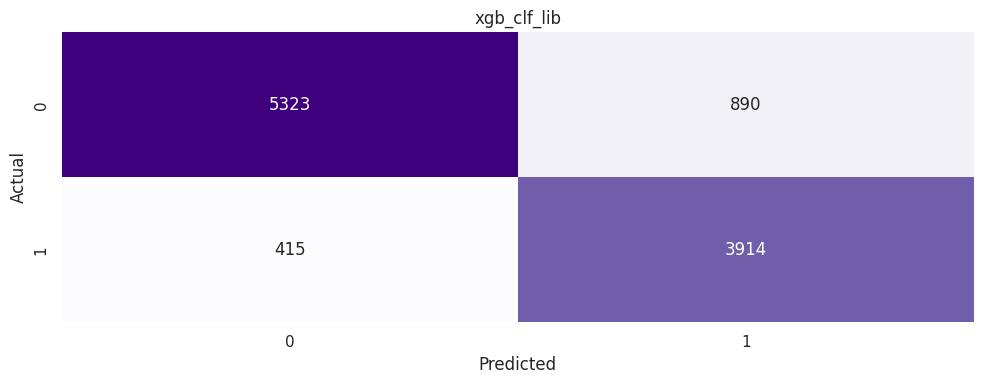

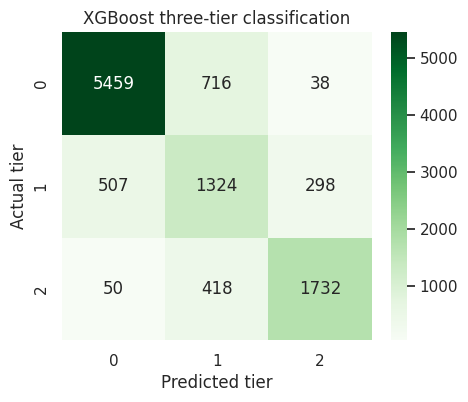

In [ ]:
plot_classification_models(["xgb_clf_lib"])
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_multi, y_pred_multi), annot=True, fmt="d", cmap="Greens")
plt.title("XGBoost three-tier classification")
plt.xlabel("Predicted tier")
plt.ylabel("Actual tier")
plt.show()

## Model Evaluation and Performance Comparison

We compile separate leaderboards for:
1. Ensemble Regression (sorted dynamically by $R^2$)
2. Ensemble Classification (sorted dynamically by F1 Score & Accuracy)
3. Time-Series Cross-Validation on top models
4. Baseline vs. Ensemble comparison on the identical chronological split

In [ ]:
reg_leaderboard_df = pd.DataFrame(reg_results).sort_values("R2_Score", ascending=False).reset_index(drop=True)
clf_leaderboard_df = pd.DataFrame(clf_results).sort_values("F1_Score", ascending=False).reset_index(drop=True)

best_reg_row = reg_leaderboard_df.iloc[0].to_dict()
best_clf_row = clf_leaderboard_df.iloc[0].to_dict()

print(f"=== ENSEMBLE REGRESSION LEADERBOARD ({len(reg_leaderboard_df)} Models) ===")
display(reg_leaderboard_df.drop(columns=["Hyperparameters"]))
print(f"Best Ensemble Regressor: {best_reg_row['Model']} (R2 = {best_reg_row['R2_Score']}, RMSE = {best_reg_row['RMSE']})")

print(f"\n=== ENSEMBLE CLASSIFICATION LEADERBOARD ({len(clf_leaderboard_df)} Models) ===")
display(clf_leaderboard_df.drop(columns=["Hyperparameters"]))
print(f"Best Ensemble Classifier: {best_clf_row['Model']} (F1 = {best_clf_row['F1_Score']}, Acc = {best_clf_row['Accuracy']}, AUC = {best_clf_row['ROC_AUC']})")

# Classification Report for Top Classifier
best_clf_id = best_clf_row["Model_ID"]
print(f"\n=== Detailed Classification Report ({best_clf_row['Model']}) ===")
print(classification_report(y_test_clf, clf_predictions[best_clf_id], target_names=["Safe/Moderate (<=100)", "Unhealthy (>100)"]))

# 5-Fold TimeSeriesSplit CV on Best Regressor and Best Classifier
cv5 = TimeSeriesSplit(n_splits=5)
cv_reg_scores = []
cv_clf_scores = []
for tr_idx, va_idx in cv5.split(X_train):
    m_r = clone(trained_pipelines[best_reg_row["Model_ID"]])
    m_r.fit(X_train.iloc[tr_idx], y_train_reg[tr_idx])
    cv_reg_scores.append(float(r2_score(y_train_reg[va_idx], m_r.predict(X_train.iloc[va_idx]))))

    m_c = clone(trained_pipelines[best_clf_id])
    m_c.fit(X_train.iloc[tr_idx], y_train_clf[tr_idx])
    cv_clf_scores.append(float(f1_score(y_train_clf[va_idx], m_c.predict(X_train.iloc[va_idx]))))

print(f"5-Fold TimeSeriesSplit CV R2 ({best_reg_row['Model']}): {np.mean(cv_reg_scores):.4f} +/- {np.std(cv_reg_scores):.4f}")
print(f"5-Fold TimeSeriesSplit CV F1 ({best_clf_row['Model']}): {np.mean(cv_clf_scores):.4f} +/- {np.std(cv_clf_scores):.4f}")

# Save CSV Leaderboards
reg_leaderboard_df.to_csv(os.path.join(PROJECT_ROOT, "dataset", "ensemble_regression_leaderboard.csv"), index=False)
clf_leaderboard_df.to_csv(os.path.join(PROJECT_ROOT, "dataset", "ensemble_classification_leaderboard.csv"), index=False)

=== ENSEMBLE REGRESSION LEADERBOARD (5 Models) ===


,Model_ID,Model,Family,Implementation,R2_Score,MSE,RMSE,MAE,Train_Time_s,Predict_Time_s
0,xgb_reg_lib,XGBoost Regressor (XGBoost),XGBoost,Library,0.7813,597.4758,24.4433,16.1603,1.0807,0.0653
1,gb_reg_lib,Gradient Boosting Regressor (Scikit-learn),Gradient Boosting,Library,0.7775,607.7588,24.6528,16.2431,38.4890,0.0347
2,rf_reg_lib,Random Forest Regressor (Scikit-learn),Random Forest,Library,0.7717,623.5875,24.9717,16.2399,20.5729,0.1877
3,gb_reg_scratch,Gradient Boosting Regressor (Scratch),Gradient Boosting,Scratch,0.7678,634.3752,25.1868,16.6334,12.0456,0.0670
4,rf_reg_scratch,Random Forest Regressor (Scratch),Random Forest,Scratch,0.7536,673.0098,25.9424,16.8566,4.3653,0.0622


Best Ensemble Regressor: XGBoost Regressor (XGBoost) (R2 = 0.7813, RMSE = 24.4433)

=== ENSEMBLE CLASSIFICATION LEADERBOARD (11 Models) ===


,Model_ID,Model,Family,Implementation,Accuracy,Precision,Recall,F1_Score,Macro_F1,Weighted_F1,ROC_AUC,Train_Time_s,Predict_Time_s
0,xgb_clf_lib,XGBoost Classifier (XGBoost),XGBoost,Library,0.8762,0.8147,0.9041,0.8571,0.8740,0.8770,0.9595,1.2316,0.0448
1,stacking_clf_lib,Stacking Classifier (Scikit-learn),Stacking,Library,0.8809,0.8496,0.8626,0.8560,0.8772,0.8810,0.9551,60.2735,2.8570
2,rf_clf_lib,Random Forest Classifier (Scikit-learn),Random Forest,Library,0.8801,0.8489,0.8614,0.8551,0.8764,0.8802,0.9568,15.8444,0.1213
3,rf_clf_scratch,Random Forest Classifier (Scratch),Random Forest,Scratch,0.8792,0.8509,0.8556,0.8533,0.8753,0.8792,0.9530,3.9712,0.0464
4,stacking_clf_scratch,Stacking Classifier (Scratch),Stacking,Scratch,0.8746,0.8269,0.8785,0.8519,0.8716,0.8751,0.9523,19.6459,4.0281
5,adaboost_clf_lib,AdaBoost Classifier (Scikit-learn),AdaBoost,Library,0.8751,0.8335,0.8695,0.8511,0.8717,0.8754,0.9549,13.8778,0.1162
6,hard_voting_clf_lib,Hard Voting Classifier (Scikit-learn),Hard Voting,Library,0.8762,0.8490,0.8496,0.8493,0.8721,0.8762,NaN,12.9678,2.8419
7,soft_voting_clf_scratch,Soft Voting Classifier (Scratch),Soft Voting,Scratch,0.8698,0.8173,0.8794,0.8472,0.8669,0.8704,0.9521,2.9063,4.4243
8,soft_voting_clf_lib,Soft Voting Classifier (Scikit-learn),Soft Voting,Library,0.8695,0.8180,0.8773,0.8466,0.8665,0.8701,0.9526,13.0142,2.8053
9,hard_voting_clf_scratch,Hard Voting Classifier (Scratch),Hard Voting,Scratch,0.8741,0.8481,0.8448,0.8464,0.8699,0.8741,0.9235,4.1812,2.7431


Best Ensemble Classifier: XGBoost Classifier (XGBoost) (F1 = 0.8571, Acc = 0.8762, AUC = 0.9595)

=== Detailed Classification Report (XGBoost Classifier (XGBoost)) ===
                       precision    recall  f1-score   support

Safe/Moderate (<=100)       0.93      0.86      0.89      6213
     Unhealthy (>100)       0.81      0.90      0.86      4329

             accuracy                           0.88     10542
            macro avg       0.87      0.88      0.87     10542
         weighted avg       0.88      0.88      0.88     10542

5-Fold TimeSeriesSplit CV R2 (XGBoost Regressor (XGBoost)): 0.6746 +/- 0.1086
5-Fold TimeSeriesSplit CV F1 (XGBoost Classifier (XGBoost)): 0.8730 +/- 0.0476


#### Combined model comparison and figure exports

In [ ]:
# 1. Regression R2, RMSE & MAE Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
reg_plot_df = reg_leaderboard_df.sort_values("R2_Score", ascending=True)
colors_reg = ["#6d28d9" if t == "Library" else "#a78bfa" for t in reg_plot_df["Implementation"]]

axes[0].barh(reg_plot_df["Model"], reg_plot_df["R2_Score"], color=colors_reg)
axes[0].set_title("Ensemble Regression R2 Score (Higher is Better)")
axes[0].set_xlabel("R2 Score")
for i, v in enumerate(reg_plot_df["R2_Score"]):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)

axes[1].barh(reg_plot_df["Model"], reg_plot_df["RMSE"], color=colors_reg)
axes[1].set_title("Ensemble Regression RMSE (Lower is Better)")
axes[1].set_xlabel("RMSE (AQI units)")
for i, v in enumerate(reg_plot_df["RMSE"]):
    axes[1].text(v + 0.4, i, f"{v:.2f}", va="center", fontsize=9)

axes[2].barh(reg_plot_df["Model"], reg_plot_df["MAE"], color=colors_reg)
axes[2].set_title("Ensemble Regression MAE (Lower is Better)")
axes[2].set_xlabel("MAE (AQI units)")
for i, v in enumerate(reg_plot_df["MAE"]):
    axes[2].text(v + 0.3, i, f"{v:.2f}", va="center", fontsize=9)

fig.suptitle("Unit 5 Ensemble Regression Comparison (Chronological Test Set)", fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig(fig, "ens_01_regression_r2_rmse_mae.png")

# 2. Actual vs Predicted AQI & Residual Analysis (Top Regressor)
best_reg_id = best_reg_row["Model_ID"]
y_pred_best = reg_predictions[best_reg_id]
residuals = y_test_reg - y_pred_best
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test_reg), size=min(2500, len(y_test_reg)), replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
axes[0].scatter(y_test_reg[sample_idx], y_pred_best[sample_idx], alpha=0.35, s=14, color="#6d28d9")
lims = [0, max(y_test_reg.max(), y_pred_best.max()) * 1.02]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Ideal y = x")
axes[0].set_title(f"Actual vs Predicted AQI\n({best_reg_row['Model']})")
axes[0].set_xlabel("Actual US AQI")
axes[0].set_ylabel("Predicted US AQI")
axes[0].legend()

sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="#12a150")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residual Distribution (Actual - Predicted)")
axes[1].set_xlabel("Residual Error (AQI)")

axes[2].scatter(y_pred_best[sample_idx], residuals[sample_idx], alpha=0.35, s=14, color="#b7791f")
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Residuals vs Predicted Values")
axes[2].set_xlabel("Predicted US AQI")
axes[2].set_ylabel("Residual (AQI)")

plt.tight_layout()
save_fig(fig, "ens_02_actual_vs_predicted_and_residuals.png")

# 3. Classification Accuracy, Precision, Recall, F1 Comparison
fig, ax = plt.subplots(figsize=(14, 6))
clf_melt = clf_leaderboard_df.melt(
    id_vars=["Model"], value_vars=["Accuracy", "Precision", "Recall", "F1_Score"],
    var_name="Metric", value_name="Score"
)
sns.barplot(data=clf_melt, x="Model", y="Score", hue="Metric", ax=ax, palette="viridis")
ax.set_ylim(0.70, 1.0)
ax.set_title("Ensemble Classification Metrics Comparison (Chronological Test Set)", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
save_fig(fig, "ens_03_classification_metrics_comparison.png")

# 4. Confusion Matrices (Top 4 Classifiers + 3-Tier Multiclass)
top4_clf = clf_leaderboard_df.head(4)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for idx, (_, r) in enumerate(top4_clf.iterrows()):
    cm = confusion_matrix(y_test_clf, clf_predictions[r["Model_ID"]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[idx],
                xticklabels=["Safe", "Risk"], yticklabels=["Safe", "Risk"])
    axes[idx].set_title(f"{r['Model']}\nF1={r['F1_Score']:.3f}", fontsize=9.5)
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

cm_multi = confusion_matrix(y_test_multi, y_pred_multi)
sns.heatmap(cm_multi, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[4],
            xticklabels=["T0", "T1", "T2"], yticklabels=["T0", "T1", "T2"])
axes[4].set_title(f"3-Tier XGBoost\nAcc={multi_acc:.3f}", fontsize=9.5)
axes[4].set_xlabel("Predicted Tier")
axes[4].set_ylabel("Actual Tier")
plt.tight_layout()
save_fig(fig, "ens_04_confusion_matrices.png")

# 5. ROC Curves & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
roc_export = {}
pr_export = {}
for _, r in clf_leaderboard_df.iterrows():
    mid = r["Model_ID"]
    if mid not in clf_probabilities:
        continue
    probs = clf_probabilities[mid]
    fpr, tpr, _ = roc_curve(y_test_clf, probs)
    prec_c, rec_c, _ = precision_recall_curve(y_test_clf, probs)
    ap = float(average_precision_score(y_test_clf, probs))

    # Downsample curves to ~80 points for compact JSON export
    step_r = max(1, len(fpr) // 80)
    step_p = max(1, len(prec_c) // 80)
    roc_export[mid] = {"label": r["Model"], "auc": r["ROC_AUC"], "fpr": np.round(fpr[::step_r], 4).tolist(), "tpr": np.round(tpr[::step_r], 4).tolist()}
    pr_export[mid] = {"label": r["Model"], "ap": round(ap, 4), "recall": np.round(rec_c[::step_p], 4).tolist(), "precision": np.round(prec_c[::step_p], 4).tolist()}

    axes[0].plot(fpr, tpr, lw=1.8, label=f"{r['Model']} (AUC={r['ROC_AUC']:.3f})")
    axes[1].plot(rec_c, prec_c, lw=1.8, label=f"{r['Model']} (AP={ap:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC Curves Across Ensemble Classifiers")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=7.5, loc="lower right")

axes[1].set_title("Precision-Recall Curves Across Ensemble Classifiers")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=7.5, loc="lower left")

plt.tight_layout()
save_fig(fig, "ens_05_roc_and_pr_curves.png")

# 6. Feature Importance (RF Reg, GB Reg, XGBoost Reg, XGBoost Clf)
def get_importances(pipe_key):
    m = trained_pipelines[pipe_key].named_steps["model"]
    imp = getattr(m, "feature_importances_", None)
    if imp is None:
        return None
    s = pd.Series(imp, index=TRANSFORMED_FEATURE_NAMES).sort_values(ascending=False)
    return s

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fi_export = {}
for ax, (pid, title) in zip(axes, [
    ("rf_reg_lib", "Random Forest Regressor (Library)"),
    ("gb_reg_lib", "Gradient Boosting Regressor (Library)"),
    ("xgb_reg_lib", "XGBoost Regressor (Library)"),
]):
    imp_s = get_importances(pid).head(12)
    fi_export[pid] = {"features": imp_s.index.tolist(), "importances": np.round(imp_s.values, 5).tolist()}
    imp_s[::-1].plot(kind="barh", ax=ax, color="#6d28d9")
    ax.set_title(f"Top 12 Features: {title}")
    ax.set_xlabel("Relative Importance")

for pid in ["rf_clf_lib", "xgb_clf_lib", "rf_reg_scratch", "gb_reg_scratch"]:
    imp_s = get_importances(pid)
    if imp_s is not None:
        fi_export[pid] = {"features": imp_s.head(12).index.tolist(), "importances": np.round(imp_s.head(12).values, 5).tolist()}

plt.tight_layout()
save_fig(fig, "ens_06_feature_importance.png")

# 7. Training Time, Prediction Time & Scratch vs Library Comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
all_bench = pd.concat([
    reg_leaderboard_df[["Model", "Implementation", "Train_Time_s", "Predict_Time_s"]],
    clf_leaderboard_df[["Model", "Implementation", "Train_Time_s", "Predict_Time_s"]],
], ignore_index=True)

all_sorted = all_bench.sort_values("Train_Time_s", ascending=True)
bar_cols = ["#a78bfa" if x == "Scratch" else "#6d28d9" for x in all_sorted["Implementation"]]
axes[0].barh(all_sorted["Model"], all_sorted["Train_Time_s"], color=bar_cols)
axes[0].set_title("Training Time Comparison (Seconds)")
axes[0].set_xlabel("Train Time (s)")

axes[1].barh(all_sorted["Model"], all_sorted["Predict_Time_s"], color=bar_cols)
axes[1].set_title("Test-Set Inference Time Comparison (10,542 Rows)")
axes[1].set_xlabel("Predict Time (s)")

plt.tight_layout()
save_fig(fig, "ens_07_timing_and_scratch_vs_lib.png")

# 8. Diagnostics: Stacking Base vs Meta, Hard vs Soft Voting, Boosting Iterations & Baseline vs Ensemble
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))

# 8a. Stacking Base Learners OOF vs Final Meta-Learner
stk_scratch_model = trained_pipelines["stacking_clf_scratch"].named_steps["model"]
oof_scores = dict(stk_scratch_model.oof_base_scores_)
oof_scores["Stacking Meta-Learner (Test)"] = float(clf_leaderboard_df.loc[clf_leaderboard_df["Model_ID"] == "stacking_clf_scratch", "Accuracy"].values[0])
axes[0, 0].bar(list(oof_scores.keys()), list(oof_scores.values()), color=["#94a3b8", "#94a3b8", "#94a3b8", "#94a3b8", "#6d28d9"])
axes[0, 0].set_ylim(0.75, 0.96)
axes[0, 0].set_title("Stacking: Base Learners (Chronological OOF) vs Meta-Learner")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].tick_params(axis="x", rotation=20)

# 8b. Gradient Boosting Staged Test MSE vs Iteration
gb_s_model = trained_pipelines["gb_reg_scratch"].named_steps["model"]
gb_l_model = trained_pipelines["gb_reg_lib"].named_steps["model"]
X_test_tree = trained_pipelines["gb_reg_lib"].named_steps["pre"].transform(X_test)
gb_s_test_mse = [float(mean_squared_error(y_test_reg, p)) for p in gb_s_model.staged_predict(X_test_tree)]
gb_l_test_mse = [float(mean_squared_error(y_test_reg, p)) for p in gb_l_model.staged_predict(X_test_tree)]
axes[0, 1].plot(range(1, len(gb_s_test_mse) + 1), gb_s_test_mse, label="Scratch GBR (Test MSE)", color="#a78bfa", lw=2)
axes[0, 1].plot(range(1, len(gb_l_test_mse) + 1), gb_l_test_mse, label="Sklearn GBR (Test MSE)", color="#6d28d9", lw=2)
axes[0, 1].set_title("Gradient Boosting: Test MSE Across Boosting Iterations")
axes[0, 1].set_xlabel("Boosting Stage (Tree #)")
axes[0, 1].set_ylabel("Test MSE")
axes[0, 1].legend()

# 8c. Baseline vs Ensemble Comparison (Chronological Split)
comp_reg = pd.concat([
    pd.DataFrame(baseline_reg_rows)[["Model", "R2_Score"]],
    reg_leaderboard_df[["Model", "R2_Score"]],
], ignore_index=True).sort_values("R2_Score", ascending=True)
c_reg = ["#94a3b8" if "Baseline" in m else "#12a150" for m in comp_reg["Model"]]
axes[1, 0].barh(comp_reg["Model"], comp_reg["R2_Score"], color=c_reg)
axes[1, 0].set_title("Baseline vs Ensemble Regression (Identical Chronological Split)")
axes[1, 0].set_xlabel("R2 Score")

# 8d. Learning Curve on Top Classifier (XGBoost Classifier)
lc_sizes, lc_tr, lc_va = learning_curve(
    clone(trained_pipelines["xgb_clf_lib"]),
    X_train, y_train_clf,
    cv=TimeSeriesSplit(n_splits=3),
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="f1",
    n_jobs=1,
)
axes[1, 1].plot(lc_sizes, np.mean(lc_tr, axis=1), "o-", label="Train F1", color="#6d28d9")
axes[1, 1].plot(lc_sizes, np.mean(lc_va, axis=1), "o-", label="TimeSeries CV F1", color="#12a150")
axes[1, 1].set_title("Learning Curve: XGBoost Classifier (TimeSeriesSplit CV)")
axes[1, 1].set_xlabel("Training Sample Size")
axes[1, 1].set_ylabel("F1 Score")
axes[1, 1].legend()

plt.tight_layout()
save_fig(fig, "ens_08_stacking_voting_boosting_diagnostics.png")
print("Saved all 8 ensemble figure suites to figures/ensemble/ and website/figures/ensemble/.")

Saved all 8 ensemble figure suites to figures/ensemble/ and website/figures/ensemble/.


## Save Models and Results

In [ ]:
# 1. Save every trained pipeline as individual .joblib artifact for zero-overhead selective loading
model_files = {}
for mid, pipe in trained_pipelines.items():
    fname = f"{mid}.joblib"
    fpath = os.path.join(ENS_MODEL_DIR, fname)
    joblib.dump(pipe, fpath, compress=3)
    model_files[mid] = os.path.relpath(fpath, PROJECT_ROOT).replace("\\", "/")

# Also save secondary 3-tier XGBoost severity pipeline
multi_path = os.path.join(ENS_MODEL_DIR, "xgb_multi_severity.joblib")
joblib.dump(xgb_multi_pipe, multi_path, compress=3)
model_files["xgb_multi_severity"] = os.path.relpath(multi_path, PROJECT_ROOT).replace("\\", "/")

# 2. Prepare compact JSON payload for interactive website charts
cm_dict = {}
for _, r in clf_leaderboard_df.iterrows():
    mid = r["Model_ID"]
    cm = confusion_matrix(y_test_clf, clf_predictions[mid])
    tn, fp, fn, tp = [int(x) for x in cm.ravel()]
    cm_dict[mid] = {
        "model": r["Model"],
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "accuracy": r["Accuracy"], "precision": r["Precision"],
        "recall": r["Recall"], "f1_score": r["F1_Score"], "roc_auc": None if pd.isna(r["ROC_AUC"]) else r["ROC_AUC"],
    }

# Representative sample of Actual vs Predicted & Residuals (1,200 points across cities)
vis_idx = np.linspace(0, len(y_test_reg) - 1, min(1200, len(y_test_reg)), dtype=int)
actual_vs_pred_export = {
    "actual": np.round(y_test_reg[vis_idx], 2).tolist(),
    "city": test_df["city"].iloc[vis_idx].tolist(),
    "time": test_df["time"].iloc[vis_idx].tolist(),
    "predictions": {
        mid: np.round(preds[vis_idx], 2).tolist()
        for mid, preds in reg_predictions.items()
    },
}

ensemble_results_json = {
    "metadata": {
        "dataset_path": "dataset/aqi_2026.csv",
        "dataset_sha256": dataset_sha256,
        "total_rows": int(len(df)),
        "train_rows": int(len(train_df)),
        "test_rows": int(len(test_df)),
        "cutoff_timestamp": str(cutoff_time),
        "split_strategy": "Chronological 80/20 split grouped by hourly timestamp (zero same-hour leakage)",
        "input_features": ALL_INPUT_FEATURES,
        "numerical_features": NUMERICAL_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "transformed_features": TRANSFORMED_FEATURE_NAMES,
        "target_note": "high_health_risk and health_risk_level are AQI-threshold-derived risk categories (AQI > 100; <=100 / 101-150 / >150), not independent clinical diagnoses.",
        "python_version": platform.python_version(),
        "sklearn_version": sklearn.__version__,
        "xgboost_version": xgb.__version__,
        "trained_at": pd.Timestamp.now().isoformat(),
        "total_ensemble_models": int(len(reg_leaderboard_df) + len(clf_leaderboard_df)),
        "scratch_count": int((reg_leaderboard_df["Implementation"] == "Scratch").sum() + (clf_leaderboard_df["Implementation"] == "Scratch").sum()),
        "library_count": int((reg_leaderboard_df["Implementation"] == "Library").sum() + (clf_leaderboard_df["Implementation"] == "Library").sum()),
    },
    "best_models": {
        "regression": best_reg_row,
        "classification": best_clf_row,
        "multiclass_severity": {
            "model_id": "xgb_multi_severity",
            "model": "XGBoost 3-Tier Severity Classifier",
            "accuracy": round(multi_acc, 4),
            "macro_f1": round(multi_macro_f1, 4),
        },
    },
    "regression_leaderboard": reg_leaderboard_df.to_dict(orient="records"),
    "classification_leaderboard": clf_leaderboard_df.to_dict(orient="records"),
    "baseline_chronological": {
        "regression": baseline_reg_rows,
        "classification": baseline_clf_rows,
    },
    "cv_scores_5fold_timeseries": {
        "regression": {"model": best_reg_row["Model"], "scores": [round(s, 4) for s in cv_reg_scores], "mean": round(float(np.mean(cv_reg_scores)), 4), "std": round(float(np.std(cv_reg_scores)), 4)},
        "classification": {"model": best_clf_row["Model"], "scores": [round(s, 4) for s in cv_clf_scores], "mean": round(float(np.mean(cv_clf_scores)), 4), "std": round(float(np.std(cv_clf_scores)), 4)},
    },
    "confusion_matrices": cm_dict,
    "roc_curves": roc_export,
    "pr_curves": pr_export,
    "feature_importances": fi_export,
    "actual_vs_predicted": actual_vs_pred_export,
    "diagnostics": {
        "stacking_oof_base_accuracies": {k: round(v, 4) for k, v in oof_scores.items()},
        "boosting_staged_test_mse": {
            "scratch": [round(x, 2) for x in gb_s_test_mse],
            "library": [round(x, 2) for x in gb_l_test_mse],
        },
        "learning_curve_xgb_clf": {
            "train_sizes": lc_sizes.tolist(),
            "train_f1_mean": np.round(np.mean(lc_tr, axis=1), 4).tolist(),
            "val_f1_mean": np.round(np.mean(lc_va, axis=1), 4).tolist(),
        },
    },
}

with open(os.path.join(PROJECT_DIR, "ensemble_results.json"), "w", encoding="utf-8") as f:
    json.dump(ensemble_results_json, f, indent=2)

# 3. Update Central Artifact Manifest (Single Source of Truth)
manifest = {"ensemble": [], "clustering": [], "pca": [], "environment": {}}
if os.path.exists(MANIFEST_PATH):
    try:
        with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
            manifest = json.load(f)
    except Exception:
        pass

manifest["environment"] = {
    "python_version": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "joblib": joblib.__version__,
    "dataset_sha256": dataset_sha256,
    "updated_at": pd.Timestamp.now().isoformat(),
}

ensemble_manifest_entries = []
for _, r in reg_leaderboard_df.iterrows():
    mid = r["Model_ID"]
    ensemble_manifest_entries.append({
        "model_id": mid,
        "display_name": r["Model"],
        "algorithm_family": r["Family"],
        "implementation_type": r["Implementation"],
        "task_type": "regression",
        "model_file": model_files[mid],
        "required_features": ALL_INPUT_FEATURES,
        "output_type": "continuous_us_aqi",
        "supports_live_inference": True,
        "metrics": {"r2_score": r["R2_Score"], "mse": r["MSE"], "rmse": r["RMSE"], "mae": r["MAE"], "train_time_s": r["Train_Time_s"], "predict_time_s": r["Predict_Time_s"]},
        "dataset_fingerprint": dataset_sha256,
        "available": os.path.exists(os.path.join(PROJECT_ROOT, model_files[mid])),
    })

for _, r in clf_leaderboard_df.iterrows():
    mid = r["Model_ID"]
    ensemble_manifest_entries.append({
        "model_id": mid,
        "display_name": r["Model"],
        "algorithm_family": r["Family"],
        "implementation_type": r["Implementation"],
        "task_type": "classification",
        "model_file": model_files[mid],
        "required_features": ALL_INPUT_FEATURES,
        "output_type": "binary_health_risk",
        "class_labels": [0, 1],
        "supports_live_inference": True,
        "supports_probabilities": mid in clf_probabilities,
        "metrics": {
            "accuracy": r["Accuracy"], "precision": r["Precision"], "recall": r["Recall"],
            "f1_score": r["F1_Score"], "macro_f1": r["Macro_F1"], "weighted_f1": r["Weighted_F1"],
            "roc_auc": None if pd.isna(r["ROC_AUC"]) else r["ROC_AUC"],
            "train_time_s": r["Train_Time_s"], "predict_time_s": r["Predict_Time_s"],
        },
        "dataset_fingerprint": dataset_sha256,
        "available": os.path.exists(os.path.join(PROJECT_ROOT, model_files[mid])),
    })

ensemble_manifest_entries.append({
    "model_id": "xgb_multi_severity",
    "display_name": "XGBoost 3-Tier Severity Classifier",
    "algorithm_family": "XGBoost",
    "implementation_type": "Library",
    "task_type": "multiclass_classification",
    "model_file": model_files["xgb_multi_severity"],
    "required_features": ALL_INPUT_FEATURES,
    "output_type": "3_tier_severity",
    "class_labels": [0, 1, 2],
    "supports_live_inference": True,
    "supports_probabilities": True,
    "metrics": {"accuracy": round(multi_acc, 4), "macro_f1": round(multi_macro_f1, 4)},
    "dataset_fingerprint": dataset_sha256,
    "available": os.path.exists(os.path.join(PROJECT_ROOT, model_files["xgb_multi_severity"])),
})

manifest["ensemble"] = ensemble_manifest_entries

for mp in [MANIFEST_PATH]:
    with open(mp, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)

print("Exported ensemble_results.json, artifact_manifest.json, and all .joblib models.")

Exported ensemble_results.json, artifact_manifest.json, and all .joblib models.
